# Høydeanalyse av mikrofolketellingen (Neuchâtel, hverdagsturer)

Denne notebooken undersøker hvordan terreng påvirker valg av transportmiddel for hverdagsturer i Neuchâtel. Analysen er delt i to deler:

1. **Del 1 – Høydeforskjell mellom start og slutt:** Netto forskjell mellom turens sluttpunkt og startpunkt (`from_trips_height_diff` = slutt − start).
2. **Del 2 – Total (akkumulert) høydeforskjell:** Hvor mye stigning og fall turen samler seg opp over alle etapper (`height_gained` / `height_lost`), uavhengig av start- og sluttpunkt.

Høydedataene er hentet fra swisstopo-APIet (se `add_height.ipynb`) og ligger i kolonnene `S_Z_CH1903` / `Z_Z_CH1903`.

## Oppsett og databehandling

Leser inn data, grupperer transportmidler, kobler etapper til turer og bygger analyse-datasettet `full_df` (én rad per tur).

In [2]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "./microcensus_filter/microcensus_ne_weekday_trips.csv"

In [3]:
# Henter høyde for ett koordinatpar fra swisstopo-APIet.
# Høydene er allerede hentet og lagret i dataene (se add_height.ipynb),
# så denne funksjonen trengs bare ved ny henting.
def get_height(easting, northing, sr="21781"):
    url = f"https://api3.geo.admin.ch/rest/services/height?easting={easting}&northing={northing}&sr={sr}"
    return requests.get(url).json()["height"]

In [4]:
# Grupperer transportmidler (wmittel) i hovedkategorier
MZ_MODE_MAP = {
    1: 'other',       # Flugzeug
    2: 'pt',       # bahn
    3: 'pt',      # postauto
    4: 'other',        # schiff
    5: 'pt',        # tram
    6: 'pt',        # bus
    7: 'pt',         # sonstiger oec
    8: 'other',         # reisecar
    9: 'car',         # auto
    10: 'other',     # lastwagen
    11: 'car_passenger',     # Taxi
    12: 'car',      # motorrad
    13: 'moped',      # mofa
    14: 'bike',      # velo
    15: 'walk',      # fuss
    16: 'other',      # ahrzeugähnliche Geräte
    17: 'other',      # anderes, weiss nicht, keine Antwort
    
}

### Innlasting og filtrering

In [5]:
# Leser inn turer og etapper, beregner netto høydeforskjell (slutt - start)
# for hele turen, og filtrerer til hovedkategoriene bil, kollektiv, sykkel og gange.
trips_df = pd.read_csv(file_path)

etappen_df = pd.read_csv("./microcensus/dataset/etappen.csv", encoding="latin1")

trips_df['height_diff'] = trips_df['Z_Z_CH1903'] - trips_df['S_Z_CH1903']

trips_df["wmittel"] = trips_df["wmittel"].map(MZ_MODE_MAP)
trips_df = trips_df[trips_df["wmittel"].isin(["car", "pt", "bike", "walk"])]

### Kombinering av turer og etapper

In [6]:
# Gir kolonnene prefiks (from_trips_/from_etappen_) og slår sammen etapper
# mot tilhørende tur (mange etapper per tur). Beregner så høydeforskjell
# per etappe (slutt - start).


trips_df.rename(columns={org: "from_trips_"+org for org in trips_df.columns if org not in ["HHNR", "WEGNR"]}, inplace=True)
etappen_df.rename(columns={org: "from_etappen_"+org for org in etappen_df.columns if org not in ["HHNR", "WEGNR"]}, inplace=True)

original_columns = trips_df.columns.tolist()
print(f"Original columns: {original_columns}")
print(etappen_df.columns.tolist())


etappen_df_combined = etappen_df.merge(trips_df, on=["HHNR", "WEGNR"], how='right')

print(f"Combined DataFrame columns: {etappen_df_combined.columns.tolist()}")

etappen_df_combined["from_etappen_height_diff"] = etappen_df_combined["from_etappen_Z_Z_CH1903"] - etappen_df_combined["from_etappen_S_Z_CH1903"]



Original columns: ['HHNR', 'from_trips_WP', 'from_trips_AUSNR', 'WEGNR', 'from_trips_DMOD', 'from_trips_f51100', 'from_trips_f51400', 'from_trips_f51100time', 'from_trips_f51400time', 'from_trips_pseudo', 'from_trips_W_X', 'from_trips_W_Y', 'from_trips_W_X_CH1903', 'from_trips_W_Y_CH1903', 'from_trips_W_QAL', 'from_trips_W_BFS', 'from_trips_W_PLZ', 'from_trips_W_Ort', 'from_trips_W_Str', 'from_trips_W_hnr', 'from_trips_W_SPRACHE', 'from_trips_W_REGION', 'from_trips_W_KANTON', 'from_trips_W_AGGLO2000', 'from_trips_W_AGGLO_GROESSE2000', 'from_trips_W_STRUKTUR_2000', 'from_trips_W_STRUKTUR_AGG_2000', 'from_trips_w_struktur_bfs9_2000', 'from_trips_W_AGGLO2012', 'from_trips_W_AGGLO_GROESSE2012', 'from_trips_W_staedt_char_2012', 'from_trips_W_stat_stadt_2012', 'from_trips_W_ISO_Staedte_MIV', 'from_trips_W_ISO_Staedte_OeV', 'from_trips_W_OeV_KLASSE', 'from_trips_W_DEGURBA', 'from_trips_S_X', 'from_trips_S_Y', 'from_trips_S_X_CH1903', 'from_trips_S_Y_CH1903', 'from_trips_S_QAL', 'from_trips_S_

### Aggregert stigning og fall per tur

In [7]:
# Aggregerer total stigning og fall per tur over alle etappene:
# height_gained = summen av alle positive etappe-forskjeller (opp),
# height_lost  = summen av alle negative etappe-forskjeller (ned).
aggregated_df = etappen_df_combined.groupby(["HHNR", "WEGNR"]).agg(
    height_gained=pd.NamedAgg(column="from_etappen_height_diff", aggfunc=lambda x: x[x > 0].sum()),
    height_lost=pd.NamedAgg(column="from_etappen_height_diff", aggfunc=lambda x: x[x < 0].sum())
).reset_index()

### Analyse-datasett (`full_df`)

In [8]:
# Ett analyse-datasett: én rad per tur med total stigning/fall,
# netto høydeforskjell (start vs. slutt) og transportmiddel.
full_df = etappen_df_combined.merge(aggregated_df, on=["HHNR", "WEGNR"], how='left')[["HHNR", "WEGNR", "height_gained", "height_lost", "from_trips_height_diff", "from_trips_wmittel" ]]


# Del 1: Høydeforskjell mellom start og slutt

Denne delen ser kun på netto høydeforskjell mellom turens start- og sluttpunkt (`from_trips_height_diff` = slutt − start). En tur som går opp 50 m og ned igjen 50 m får dermed verdien 0 — den totale innsatsen fanges ikke opp her (det gjør Del 2).

### Fordeling per transportmiddel (fiolinplott)

/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_61130/4256528117.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


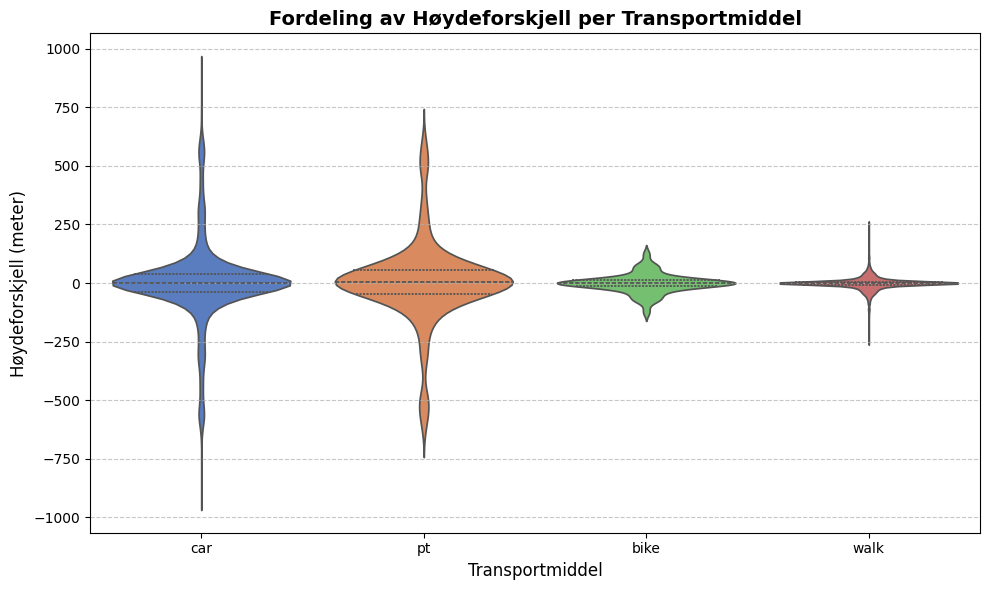

In [9]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=trips_df, 
    x="from_trips_wmittel", 
    y="from_trips_height_diff", 
    order=["car", "pt", "bike", "walk"],
    palette="muted",
    inner="quartile"  # Viser stiplete linjer for kvartiler inni fiolinen
)

plt.title("Fordeling av Høydeforskjell per Transportmiddel", fontsize=14, fontweight="bold")
plt.xlabel("Transportmiddel", fontsize=12)
plt.ylabel("Høydeforskjell (meter)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

### Tetthetsplott per transportmiddel

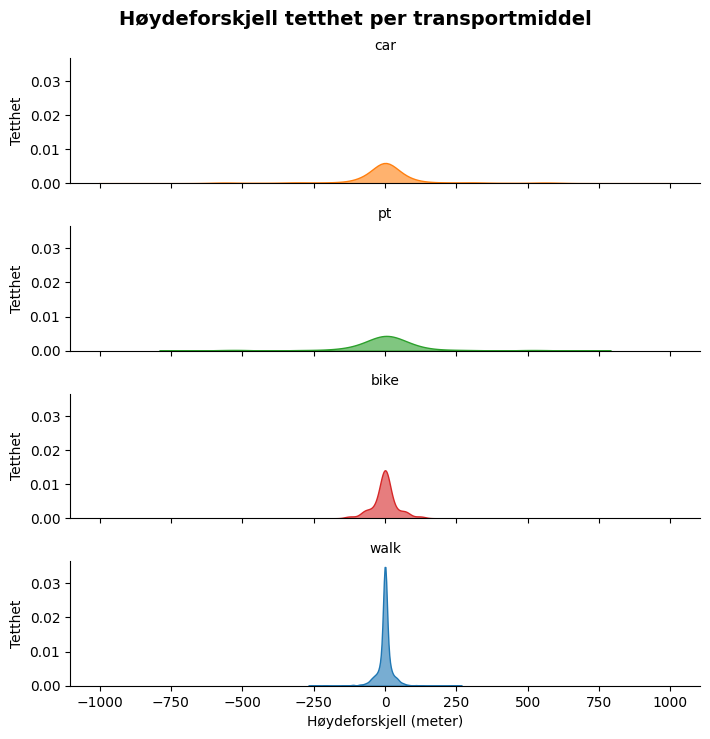

In [10]:
g = sns.FacetGrid(
    trips_df, 
    row="from_trips_wmittel", 
    hue="from_trips_wmittel", 
    row_order=["car", "pt", "bike", "walk"],
    aspect=4, 
    height=1.8
)

g.map_dataframe(sns.kdeplot, x="from_trips_height_diff", fill=True, alpha=0.6)
g.set_titles(row_template="{row_name}")
g.set_axis_labels("Høydeforskjell (meter)", "Tetthet")
g.fig.suptitle("Høydeforskjell tetthet per transportmiddel", y=1.02, fontsize=14, fontweight="bold")

plt.show()

In [11]:
# Antall turer per transportmiddel (trips_df har én rad per tur)
trips_per_mode = trips_df["from_trips_wmittel"].value_counts()
trips_per_mode_pct = trips_df["from_trips_wmittel"].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    "Antall turer": trips_per_mode,
    "Andel (%)": trips_per_mode_pct.round(2)
})

print(f"Totalt antall turer: {len(trips_df)}\n")
print(summary)

Totalt antall turer: 6370

                    Antall turer  Andel (%)
from_trips_wmittel                         
car                         3424      53.75
walk                        2128      33.41
pt                           691      10.85
bike                         127       1.99


### Detaljert fordeling per 5-meters intervall

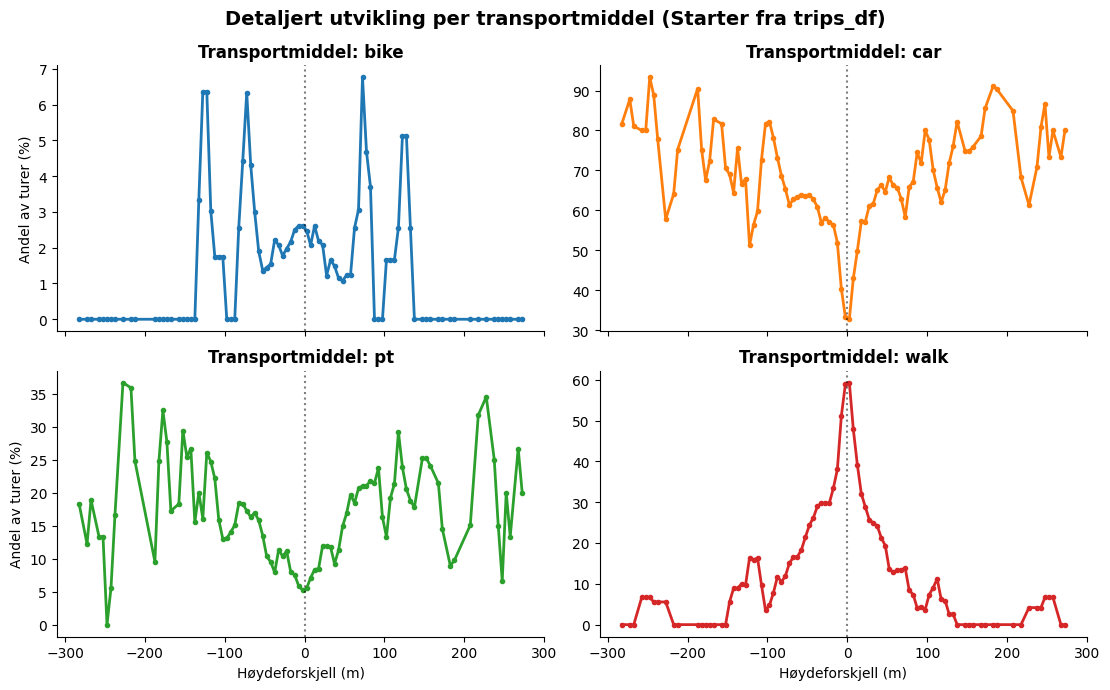

In [12]:
# 1. Velg høydespenn og stegstørrelse
min_h, max_h = -300, 300
step = 5

# 2. Filtrer trips_df og opprett kopi
mask = trips_df["from_trips_height_diff"].between(min_h, max_h)
plot_df = trips_df[mask].copy()

# 3. Opprett høydeintervaller (bins)
bins = np.arange(min_h, max_h + step, step)
plot_df["height_bin"] = pd.cut(plot_df["from_trips_height_diff"], bins=bins)

# 4. Tell totalt antall turer per intervall (for å sortere bort støy på kantsidene)
trip_counts = plot_df.groupby("height_bin", observed=False).size()

# 5. Beregn prosentvis fordeling
dist_fine = pd.crosstab(
    plot_df["height_bin"], 
    plot_df["from_trips_wmittel"], 
    normalize="index"
) * 100

# Fyll inn NaN med 0 der et transportmiddel mangler turer i et intervall
dist_fine = dist_fine.fillna(0)

# Filtrer ut intervaller med færre enn 5 turer totalt for å unngå ekstremstøy
valid_bins = trip_counts[trip_counts >= 5].index
dist_fine = dist_fine.loc[valid_bins]

# Sett midtpunkt for hvert intervall som x-akse
bin_centers = [b.mid for b in dist_fine.index]
dist_fine.index = bin_centers

# 6. Glatt ut kurvene med rullende gjennomsnitt (min_periods=1 forhindrer at linjene kutter)
dist_smoothed = dist_fine.rolling(window=3, center=True, min_periods=1).mean()

# 7. Omform til langformat for FacetGrid
dist_long = dist_smoothed.reset_index().melt(
    id_vars="index", 
    var_name="wmittel", 
    value_name="percentage"
)
dist_long.rename(columns={"index": "height_diff"}, inplace=True)

# 8. Visualiser med Seaborn FacetGrid
g = sns.FacetGrid(
    dist_long, 
    col="wmittel", 
    hue="wmittel", 
    col_wrap=2, 
    height=3.5, 
    aspect=1.6, 
    sharey=False  # Fristiller y-aksene slik at detaljer for sykkel/gange forstørres
)

g.map(plt.plot, "height_diff", "percentage", marker="o", markersize=3, linewidth=2)
g.map(plt.axvline, x=0, color="black", linestyle=":", alpha=0.5)

g.set_axis_labels("Høydeforskjell (m)", "Andel av turer (%)")
g.set_titles(col_template="Transportmiddel: {col_name}", size=12, weight="bold")

plt.subplots_adjust(top=0.9)
g.fig.suptitle("Detaljert utvikling per transportmiddel (Starter fra trips_df)", fontsize=14, fontweight="bold")

plt.show()

### Sykkelandel som funksjon av høydeforskjell (regresjon)

Tilsvarende regresjon som i Del 2, men med netto høydeforskjell mellom start og slutt (`from_trips_height_diff`) som forklaringsvariabel. Negative verdier betyr at turen slutter lavere enn den startet (nedoverbakke).

--- RESULTAT REGRESJON (-150 til 150m) ---
a (stigningstall):  -0.0012 (%-poeng per meter høydeforskjell)
b (skjæringspunkt): 1.48%


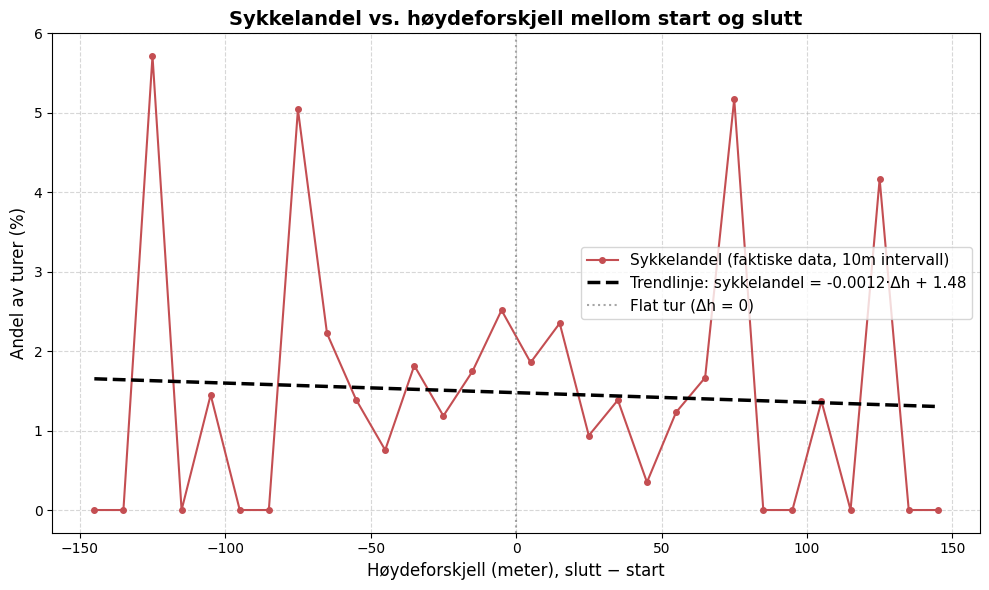

In [13]:
# 1. Definer fine intervaller (10 meters steg) over et symmetrisk spenn
min_h, max_h = -150, 150
step = 10
bins = np.arange(min_h, max_h + step, step)

# 2. Filtrer dataene og lag intervaller for from_trips_height_diff
df_hd = full_df[full_df["from_trips_height_diff"].between(min_h, max_h)].copy()
df_hd["height_bin"] = pd.cut(df_hd["from_trips_height_diff"], bins=bins)

# Beregn totalt antall turer per intervall for å kreve et minimum av observasjoner (unngår støy på kantsidene)
counts_per_bin = df_hd.groupby("height_bin", observed=False).size()

# Beregn andel sykkel (%) per intervall
dist_hd = pd.crosstab(
    df_hd["height_bin"],
    df_hd["from_trips_wmittel"],
    normalize="index"
) * 100

# Fyll inn 0 der sykkel mangler og filtrer bort intervaller med færre enn 5 turer totalt
dist_hd = dist_hd.fillna(0)
valid_bins = counts_per_bin[counts_per_bin >= 5].index
dist_hd = dist_hd.loc[valid_bins]

# Hent midtpunkter for x-aksen
x_vals = np.array([b.mid for b in dist_hd.index])
y_bike = dist_hd["bike"].values if "bike" in dist_hd.columns else np.zeros_like(x_vals)

# 3. Beregn trendlinje (lineær regresjon) over hele spennet (-150 til 150 m)
# Lineær tilpasning: sykkelandel = a*x + b
#   a = stigningstallet (%-poeng endring i sykkelandel per meter høydeforskjell)
#   b = skjæringspunktet (forventet sykkelandel ved flat tur, Δh = 0)
a, b = np.polyfit(x_vals, y_bike, 1)

print("--- RESULTAT REGRESJON (-150 til 150m) ---")
print(f"a (stigningstall):  {a:.4f} (%-poeng per meter høydeforskjell)")
print(f"b (skjæringspunkt): {b:.2f}%")

# 4. Visualisering
plt.figure(figsize=(10, 6))

# Plot faktisk sykkelandel (datapunkter og fin linje)
plt.plot(x_vals, y_bike, marker="o", color="#c44e52", markersize=4, linewidth=1.5, label="Sykkelandel (faktiske data, 10m intervall)")

# Plot trendlinjen over hele spennet
y_trend_fit = a * x_vals + b
plt.plot(
    x_vals,
    y_trend_fit,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label=f"Trendlinje: sykkelandel = {a:.4f}\u00b7\u0394h + {b:.2f}"
)

plt.axvline(0, color="gray", linestyle=":", alpha=0.7, label="Flat tur (\u0394h = 0)")

plt.title("Sykkelandel vs. høydeforskjell mellom start og slutt", fontsize=14, fontweight="bold")
plt.xlabel("Høydeforskjell (meter), slutt \u2212 start", fontsize=12)
plt.ylabel("Andel av turer (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

# Del 2: Total (akkumulert) høydeforskjell

I motsetning til Del 1 ser denne delen på **total** stigning og fall: for hver tur summeres alle positive etappe-forskjeller til `height_gained` (opp) og alle negative til `height_lost` (ned). En rundtur som starter og slutter samme sted kan dermed ha stor akkumulert stigning, selv om netto forskjell (Del 1) er null.

### Stigning vs. fall per transportmiddel

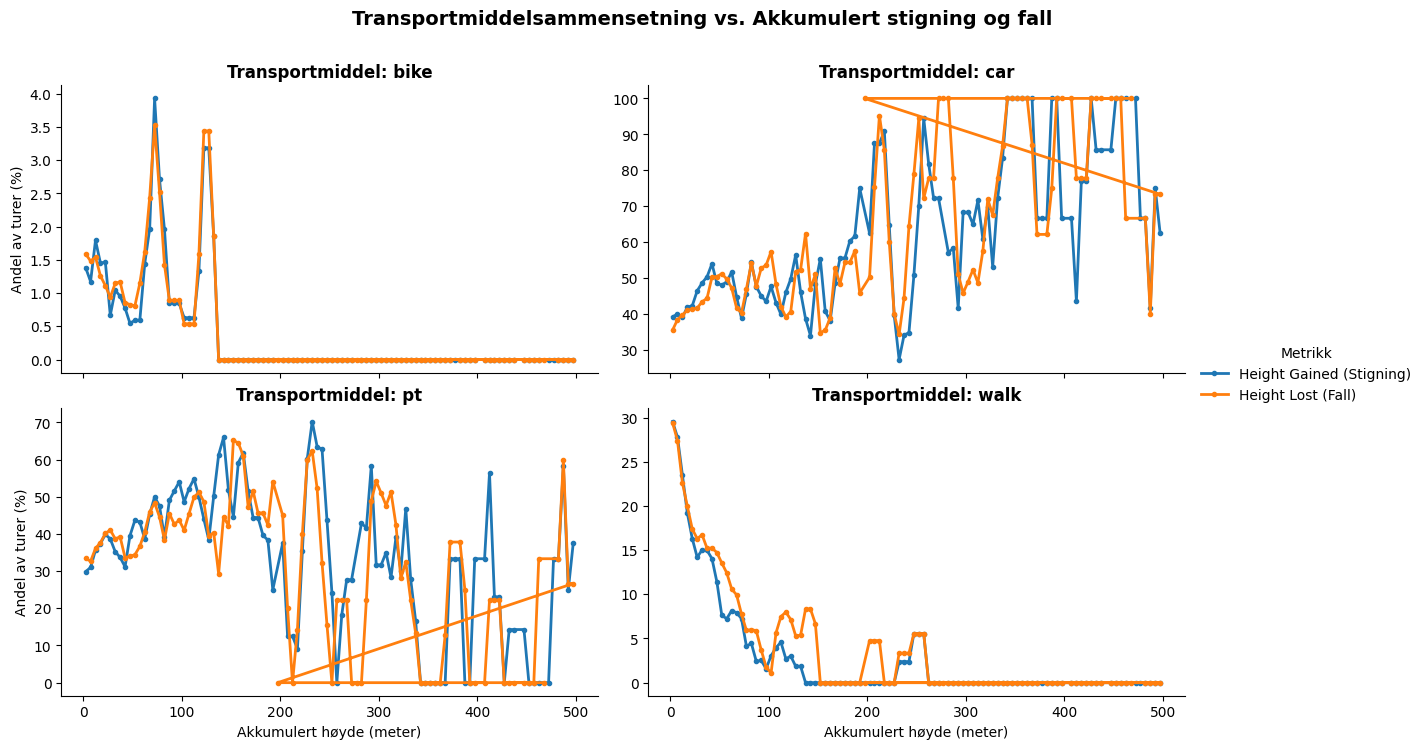

In [14]:
# Sørg for at height_lost er positiv for bedre sammenligning på aksene
full_df["height_lost_abs"] = full_df["height_lost"].abs()

# 2. Velg høydespenn (0 til 500 meters stigning/fall) og stegstørrelse (5m)
max_h = 500
step = 5
bins = np.arange(0, max_h + step, step)

# 3. Omform til lang-format for å analysere gained og lost i samme operasjon
melted_df = full_df.melt(
    id_vars=["HHNR", "WEGNR", "from_trips_wmittel"],
    value_vars=["height_gained", "height_lost_abs"],
    var_name="metric",
    value_name="height_val"
)

# Filtrer innenfor definert høydespenn
mask = melted_df["height_val"].between(0, max_h)
plot_df = melted_df[mask].copy()

# 4. Opprett intervaller (bins)
plot_df["height_bin"] = pd.cut(plot_df["height_val"], bins=bins)

# Tell antall turer per intervall og metrikk for å fjerne støy på kantsidene
trip_counts = plot_df.groupby(["metric", "height_bin"], observed=False).size()

# 5. Beregn prosentvis fordeling per metrikk (gained vs lost)
dist_fine = pd.crosstab(
    index=[plot_df["metric"], plot_df["height_bin"]],
    columns=plot_df["from_trips_wmittel"],
    normalize="index"
) * 100

dist_fine = dist_fine.fillna(0)

# Sett midtpunkt for hvert intervall på x-aksen
bin_centers = [b.mid for b in dist_fine.index.get_level_values("height_bin")]
dist_fine.index = pd.MultiIndex.from_arrays(
    [dist_fine.index.get_level_values("metric"), bin_centers],
    names=["metric", "height_val"]
)

# 6. Glatt ut kurvene per metrikk
dist_smoothed = (
    dist_fine.groupby("metric")
    .apply(lambda x: x.droplevel(0).rolling(window=3, center=True, min_periods=1).mean())
    .reset_index()
)

# Omform til langformat for FacetGrid
dist_long = dist_smoothed.melt(
    id_vars=["metric", "height_val"],
    var_name="wmittel",
    value_name="percentage"
)

# 7. Visualiser med Seaborn FacetGrid (Kolonner = transportmiddel, Farge/Stil = gained vs lost)
g = sns.FacetGrid(
    dist_long, 
    col="wmittel", 
    hue="metric", 
    col_wrap=2, 
    height=3.8, 
    aspect=1.6, 
    sharey=False  # Fristilt y-akse for å fremheve sykkel og gange
)

g.map(plt.plot, "height_val", "percentage", marker="o", markersize=3, linewidth=2)

g.set_axis_labels("Akkumulert høyde (meter)", "Andel av turer (%)")
g.set_titles(col_template="Transportmiddel: {col_name}", size=12, weight="bold")
g.add_legend(title="Metrikk", labels=["Height Gained (Stigning)", "Height Lost (Fall)"])

plt.subplots_adjust(top=0.88)
g.fig.suptitle("Transportmiddelsammensetning vs. Akkumulert stigning og fall", fontsize=14, fontweight="bold")

plt.show()

### Sykkelandel som funksjon av total stigning (regresjon)

--- RESULTAT REGRESJON (0-150m) ---
Stigningstall (Slope): -0.0012 (% poeng per meter stigning)
Skjæringspunkt (Intercept): 1.34%


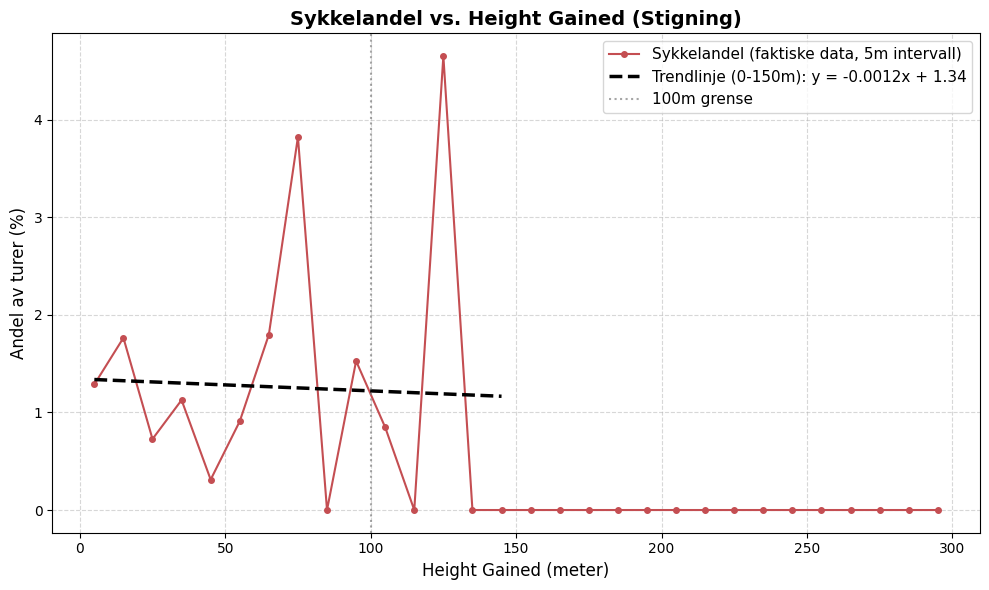

In [15]:
# 1. Definer fine intervaller (10 meters steg)
max_h = 300
step = 10
bins = np.arange(0, max_h + step, step)

# 2. Filtrer dataene og lag intervaller for height_gained
df_gained = full_df[full_df["height_gained"].between(0, max_h)].copy()
df_gained["height_bin"] = pd.cut(df_gained["height_gained"], bins=bins)

# Beregn totalt antall turer per intervall for å kreve et minimum av observasjoner (unngår støy på halen)
counts_per_bin = df_gained.groupby("height_bin", observed=False).size()

# Beregn andel sykkel (%) per intervall
dist_gained = pd.crosstab(
    df_gained["height_bin"], 
    df_gained["from_trips_wmittel"], 
    normalize="index"
) * 100

# Fyll inn 0 der sykkel mangler og filtrer bort intervaller med færre enn 5 turer totalt
dist_gained = dist_gained.fillna(0)
valid_bins = counts_per_bin[counts_per_bin >= 5].index
dist_gained = dist_gained.loc[valid_bins]

# Hent midtpunkter for x-aksen
x_vals = np.array([b.mid for b in dist_gained.index])
y_bike = dist_gained["bike"].values if "bike" in dist_gained.columns else np.zeros_like(x_vals)

# 3. Beregn trendlinje (lineær regresjon) i intervallet 0 til 150 meter
mask_0_150 = (x_vals >= 0) & (x_vals <= 150)
x_trend = x_vals[mask_0_150]
y_trend = y_bike[mask_0_150]

# Lineær tilpasning: y = a*x + b  --> a er stigningstallet (slope)
slope, intercept = np.polyfit(x_trend, y_trend, 1)

print(f"--- RESULTAT REGRESJON (0-150m) ---")
print(f"Stigningstall (Slope): {slope:.4f} (% poeng per meter stigning)")
print(f"Skjæringspunkt (Intercept): {intercept:.2f}%")

# 4. Visualisering
plt.figure(figsize=(10, 6))

# Plot faktisk sykkelandel (datapunkter og fin linje)
plt.plot(x_vals, y_bike, marker="o", color="#c44e52", markersize=4, linewidth=1.5, label="Sykkelandel (faktiske data, 5m intervall)")

# Plot trendlinjen i intervallet 0 til 150m
y_trend_fit = slope * x_trend + intercept
plt.plot(
    x_trend, 
    y_trend_fit, 
    color="black", 
    linestyle="--", 
    linewidth=2.5, 
    label=f"Trendlinje (0-150m): y = {slope:.4f}x + {intercept:.2f}"
)

plt.axvline(100, color="gray", linestyle=":", alpha=0.7, label="100m grense")

plt.title("Sykkelandel vs. Height Gained (Stigning)", fontsize=14, fontweight="bold")
plt.xlabel("Height Gained (meter)", fontsize=12)
plt.ylabel("Andel av turer (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()